<a href="https://colab.research.google.com/github/Aldors37/DataVisualization_2318046/blob/main/2318046DataVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

from google.colab import files
uploaded = files.upload()

Saving cafe_sales_clean_enriched.csv to cafe_sales_clean_enriched.csv


In [2]:
df = pd.read_csv('cafe_sales_clean_enriched.csv')

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

df.head()

Jumlah baris: 10000
Jumlah kolom: 13


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Year,Month,Day,Day of Week,Revenue Category
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,2023,9,8,Friday,Rendah
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,2023,5,16,Tuesday,Sedang
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,2023,7,19,Wednesday,Rendah
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27,2023,4,27,Thursday,Rendah
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,2023,6,11,Sunday,Rendah


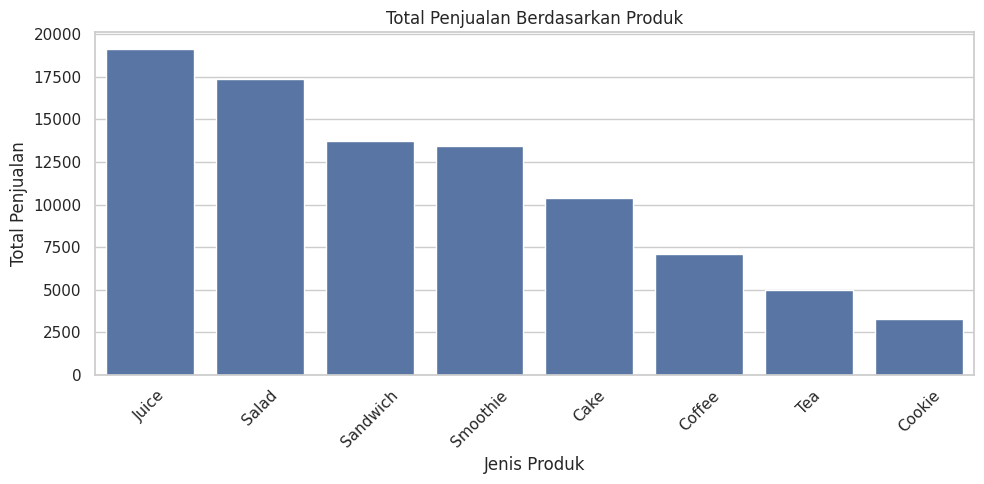

Produk dengan total penjualan tertinggi: Juice
Total penjualan: 19157.0


In [3]:
penjualan_produk = df.groupby('Item')['Total Spent'].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=penjualan_produk.index,
    y=penjualan_produk.values
)

plt.title('Total Penjualan Berdasarkan Produk')
plt.xlabel('Jenis Produk')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Produk dengan total penjualan tertinggi:",
      penjualan_produk.idxmax())
print("Total penjualan:",
      penjualan_produk.max())

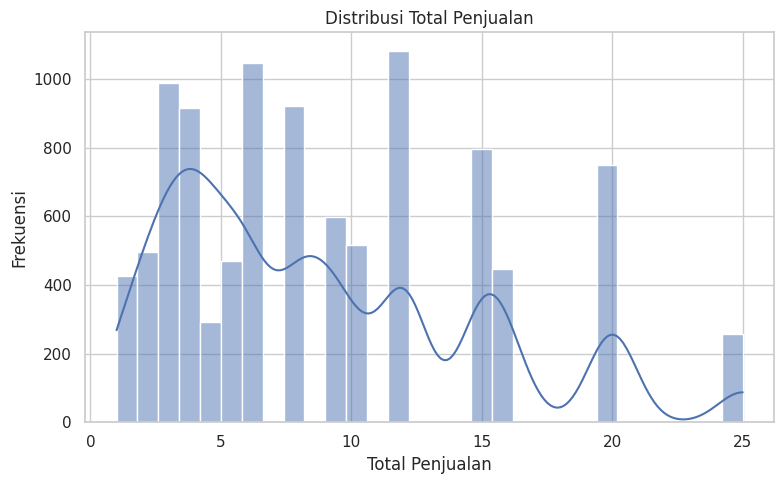

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Total Spent', bins=30, kde=True)

plt.title('Distribusi Total Penjualan')
plt.xlabel('Total Penjualan')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

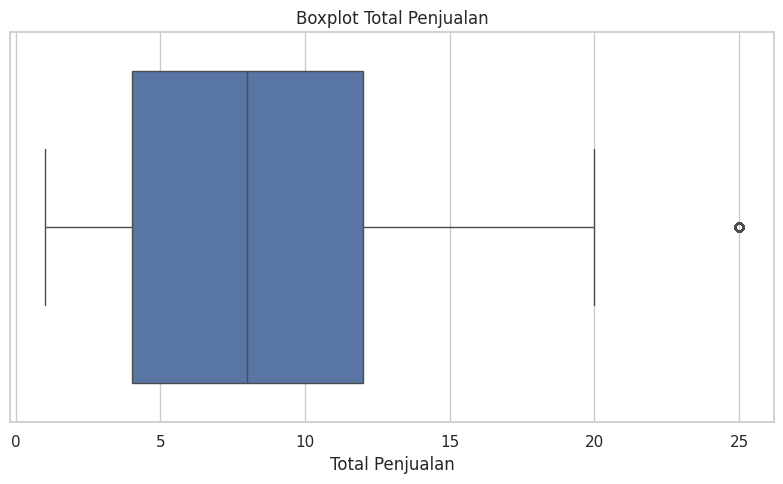

In [5]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Total Spent')

plt.title('Boxplot Total Penjualan')
plt.xlabel('Total Penjualan')
plt.tight_layout()
plt.show()

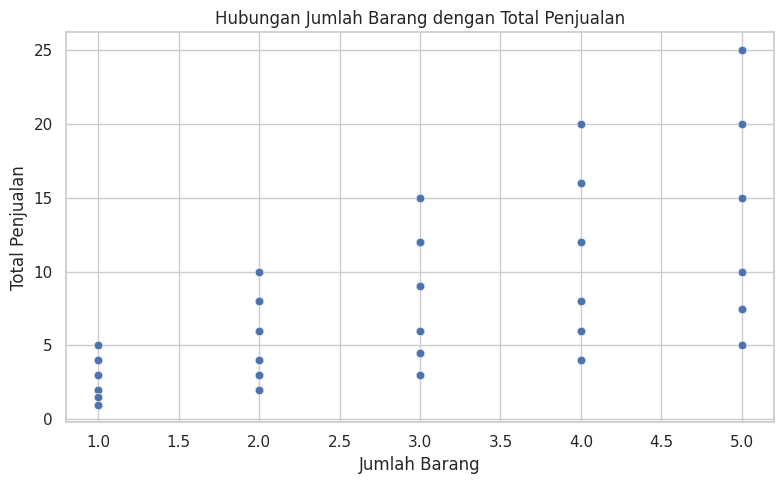

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total Spent',
    alpha=0.5
)

plt.title('Hubungan Jumlah Barang dengan Total Penjualan')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total Penjualan')
plt.tight_layout()
plt.show()

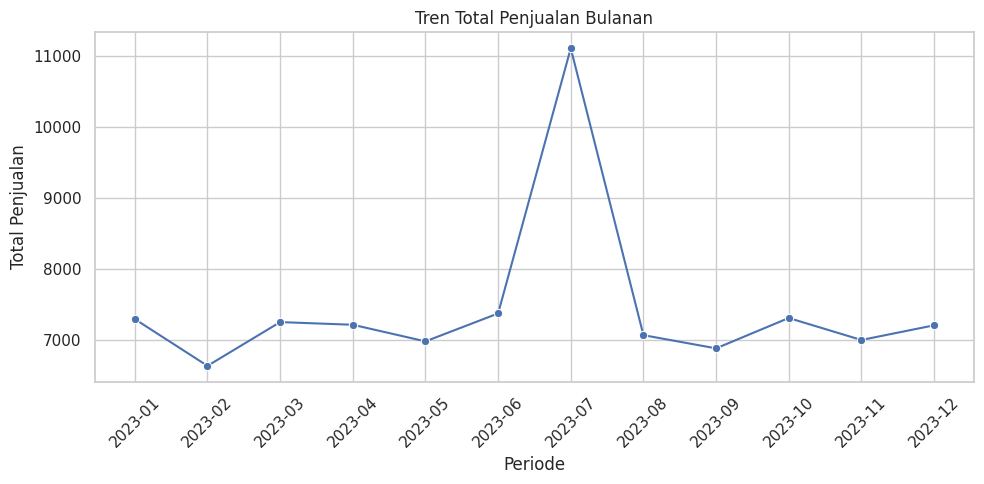

In [7]:
penjualan_bulanan = (
    df.groupby(['Year', 'Month'])['Total Spent']
    .sum()
    .reset_index()
)

penjualan_bulanan['Periode'] = (
    penjualan_bulanan['Year'].astype(str) + '-' +
    penjualan_bulanan['Month'].astype(str).str.zfill(2)
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=penjualan_bulanan,
    x='Periode',
    y='Total Spent',
    marker='o'
)

plt.title('Tren Total Penjualan Bulanan')
plt.xlabel('Periode')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

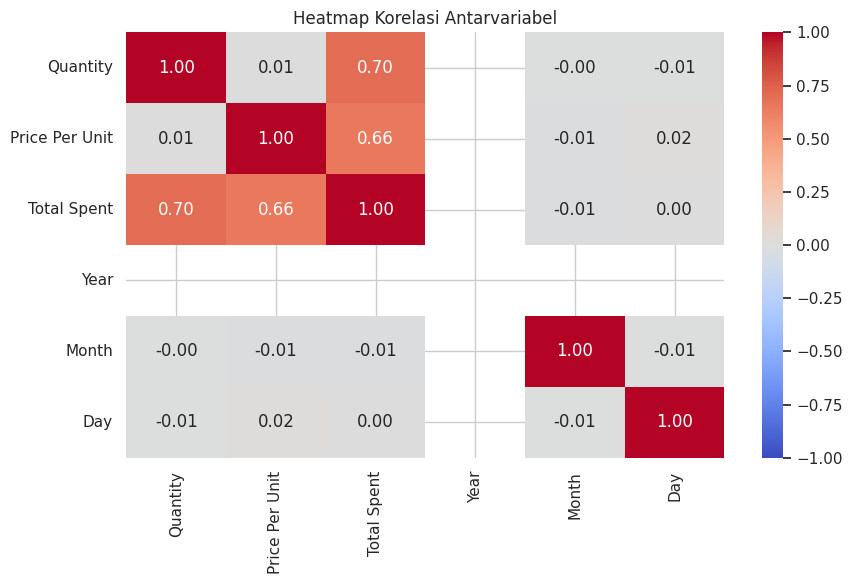

In [8]:
kolom_numerik = [
    'Quantity',
    'Price Per Unit',
    'Total Spent',
    'Year',
    'Month',
    'Day'
]

korelasi = df[kolom_numerik].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    korelasi,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Heatmap Korelasi Antarvariabel')
plt.tight_layout()
plt.show()

In [10]:
from google.colab import files

# Simpan data analisis penjualan bulanan ke file CSV terlebih dahulu
penjualan_bulanan.to_csv('penjualan_bulanan.csv', index=False)

# Unduh file CSV tersebut ke komputer Anda
files.download('penjualan_bulanan.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>